In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [4]:
df = pd.read_csv(
    "../data/processed/supervised_features.csv",
    parse_dates=["Date"]
)

df = df.sort_values(["Date", "Store"]).reset_index(drop=True)

print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

df.head()

Shape: (810942, 20)
Date range: 2013-01-31 00:00:00 to 2015-07-31 00:00:00


,Date,Sales,Store,Promo,SchoolHoliday,day_of_week,day_of_month,month,week_of_year,lag_1,lag_7,lag_14,lag_30,rolling_7,rolling_14,rolling_30,StateHoliday_0,StateHoliday_a,StateHoliday_b,StateHoliday_c
0,2013-01-31,6358,85,0,0,3,31,1,5,5050.0,6768.0,4973.0,4220.0,6058.000000,6579.642857,6621.800000,1,0,0,0
1,2013-01-31,19405,262,0,0,3,31,1,5,16092.0,19255.0,16275.0,17267.0,18099.000000,18412.857143,18235.900000,1,0,0,0
2,2013-01-31,2447,274,0,0,3,31,1,5,2146.0,2392.0,2098.0,3102.0,2595.285714,2494.928571,2378.266667,1,0,0,0
3,2013-01-31,14819,335,0,0,3,31,1,5,12944.0,15533.0,11767.0,2401.0,11753.142857,12686.357143,12138.166667,1,0,0,0
4,2013-01-31,3424,353,0,0,3,31,1,5,3129.0,3178.0,3187.0,3139.0,3348.428571,3354.285714,3164.400000,1,0,0,0


In [3]:
split_date = df["Date"].quantile(0.8)

train_df = df[df["Date"] < split_date].copy()
test_df = df[df["Date"] >= split_date].copy()

print("Split date:", split_date)
print("Train rows:", len(train_df))
print("Test rows:", len(test_df))

Split date: 2015-02-06 00:00:00
Train rows: 648146
Test rows: 162796


In [5]:
# Sales is the value we want to predict
target = "Sales"

# Date is used for splitting, not as a model input
feature_cols = [
    col for col in df.columns
    if col not in ["Date", "Sales"]
]

X_train = train_df[feature_cols]
y_train = train_df[target]

X_test = test_df[feature_cols]
y_test = test_df[target]

print("Number of features:", len(feature_cols))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Number of features: 18
Training shape: (648146, 18)
Testing shape: (162796, 18)
Missing values in X_train: 0
Missing values in X_test: 0


In [6]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training complete!")

Random Forest training complete!


In [9]:
rf_predictions = rf_model.predict(X_test)

print("First 10 predictions:")
print(rf_predictions[:10])

First 10 predictions:
[ 5080.7686754   5590.77997402  7339.0779752  10265.29850906
  5217.60173431  5362.71161576  8950.81534305  6850.29908869
  7393.90824891  5947.10983944]


In [10]:
def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    denominator = np.abs(y_true) + np.abs(y_pred)

    return np.mean(
        np.divide(
            2 * np.abs(y_true - y_pred),
            denominator,
            out=np.zeros_like(denominator),
            where=denominator != 0
        )
    ) * 100


rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = mean_squared_error(y_test, rf_predictions) ** 0.5
rf_smape = smape(y_test, rf_predictions)

print("Random Forest MAE :", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Random Forest sMAPE:", round(rf_smape, 2), "%")

Random Forest MAE : 710.63
Random Forest RMSE: 1036.48
Random Forest sMAPE: 10.51 %


In [11]:
predictions_df = test_df[["Date", "Store", "Sales"]].copy()

predictions_df["RF_Prediction"] = rf_predictions

predictions_df.to_csv(
    "../data/processed/random_forest_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


In [12]:
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
12,rolling_14,0.537677
7,lag_1,0.156973
1,Promo,0.129566
3,day_of_week,0.061530
13,rolling_30,0.033917
4,day_of_month,0.025960
6,week_of_year,0.013466
10,lag_30,0.008812
11,rolling_7,0.008804
8,lag_7,0.006890


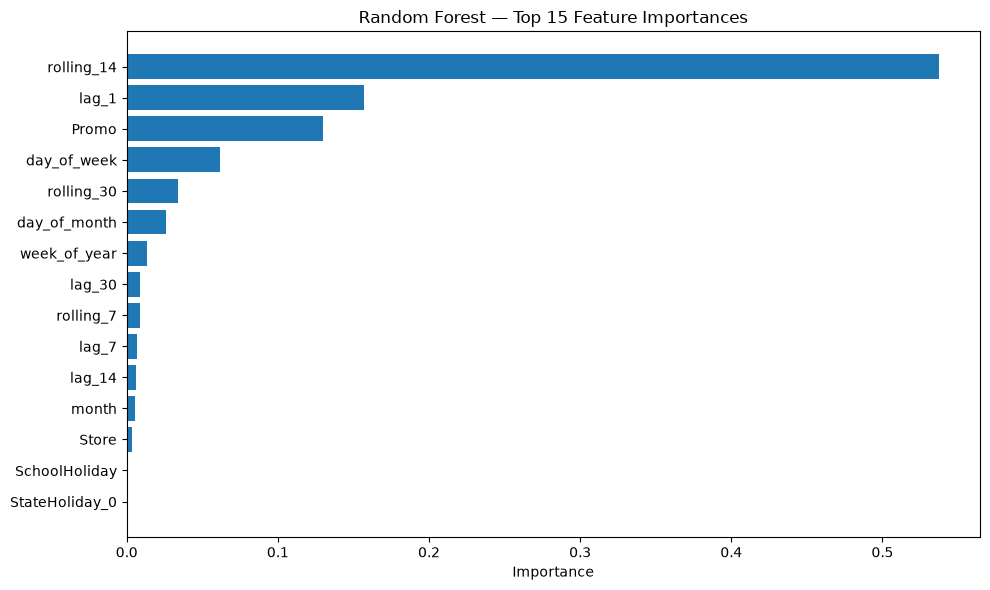

In [13]:
importance_top = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(importance_top["Feature"], importance_top["Importance"])
plt.title("Random Forest — Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [14]:
rf_results = pd.DataFrame([{
    "Model": "Random Forest",
    "MAE": rf_mae,
    "RMSE": rf_rmse,
    "sMAPE": rf_smape
}])

rf_results.to_csv(
    "../data/processed/day9_random_forest_evaluation.csv",
    index=False
)

print(rf_results.round(2))

           Model     MAE     RMSE  sMAPE
0  Random Forest  710.63  1036.48  10.51


# Day 9 — Random Forest Forecasting Baseline

## Objective
Build a machine-learning forecasting baseline using store, calendar, promotion, holiday, lag and rolling features.

## Model
Random Forest Regressor with a fixed random seed and limited tree depth.

## Evaluation
The model was evaluated on a chronological holdout using MAE, RMSE and sMAPE.

## Outputs
- random_forest_predictions.csv
- day9_random_forest_evaluation.csv

## Feature Importance
Feature importance was inspected to understand which inputs contributed most to the fitted model.

## Limitation
These metrics describe this particular validation setup. A rigorous model comparison requires identical dates, target definitions and forecast horizons across models.